# NumCompute Framework: Streaming & Prequential Evaluation Demo
This notebook demonstrates the end-to-end streaming capabilities of the NumCompute framework, including custom I/O loading, chunk-wise incremental training, and prequential evaluation visualized via the `visualise` module.

## 1. Imports & Data Loading via io.py

In [9]:
import numpy as np
import matplotlib.pyplot as plt
from numcompute_stream.io import load_csv
from numcompute_stream.pipeline import Pipeline
from numcompute_stream.preprocessing import SimpleImputer, StandardScaler
from numcompute_stream.tree import DecisionTreeClassifier
from numcompute_stream.stream import StreamEvaluator
from numcompute_stream.metrics import StreamingAccuracy
from numcompute_stream import visualise

np.random.seed(42)
num_samples = 150
X_synthetic = np.random.randn(num_samples, 3)
X_synthetic[10, 0] = np.nan
X_synthetic[45, 2] = np.nan
X_synthetic[100, 1] = np.nan

y_synthetic = np.random.choice([0, 1], size=(num_samples, 1))
dataset = np.hstack((X_synthetic, y_synthetic))

header_string = "feature1,feature2,feature3,target"
np.savetxt("data_stream.csv", dataset, delimiter=",", header=header_string, comments="", fmt="%.4f")

data = load_csv("data_stream.csv", delimiter=",", skiprows=1)
X = data[:, :-1]
y = data[:, -1].astype(int)

## 2. Chunk-wise Streaming Simulation

In [16]:
def create_stream_chunks(X, y, chunk_size=15):
    """Split dataset into sequential chunks to simulate a streaming environment."""
    n_samples = len(X)
    stream = []
    for start_idx in range(0, n_samples, chunk_size):
        end_idx = min(start_idx + chunk_size, n_samples)
        X_chunk = X[start_idx:end_idx]
        y_chunk = y[start_idx:end_idx]
        stream.append((X_chunk, y_chunk))
    return stream

stream_chunks = create_stream_chunks(X, y, chunk_size=15)

## 3. Incremental Training & Benchmarking Buffer Sizes

In [17]:
buffer_sizes = [10, 50, 200]
evaluation_results = {}

for b_size in buffer_sizes:
    pipeline = Pipeline([
        ('imputer', SimpleImputer(strategy="mean")),
        ('scaler', StandardScaler()),
        ('classifier', DecisionTreeClassifier(max_depth=4, buffer_size=b_size))
    ])
    
    evaluator = StreamEvaluator(pipeline, StreamingAccuracy())
    history = evaluator.evaluate_stream(stream_chunks)
    evaluation_results[b_size] = history

## 4. Visualisation via visualise.py

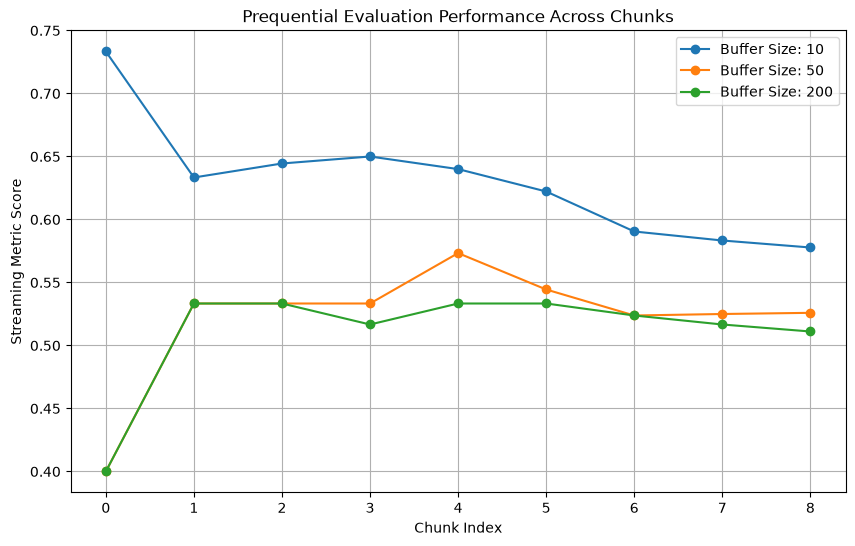

In [18]:
visualise.plot_streaming_metrics(evaluation_results)